In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

df = housing.frame


In [19]:
print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [20]:
print(df.shape)

(20640, 9)


In [21]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None


In [22]:
print(df.describe())

             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100     52.000000    141.909091     34.066667  35682.000000   

           AveOccup      Latitude     Longitude   MedHouseVal  
count  20640.000000  20640.000000  20640.000000  20640.000000  
mean       3.070655     35.631861   -119.569704      2.068558  
std       10.386050      2.135952      2.003532      1.153956  
min        0.692308     32.54000

In [24]:
print(df.isnull().sum())

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [25]:
print(df.duplicated().sum())

0


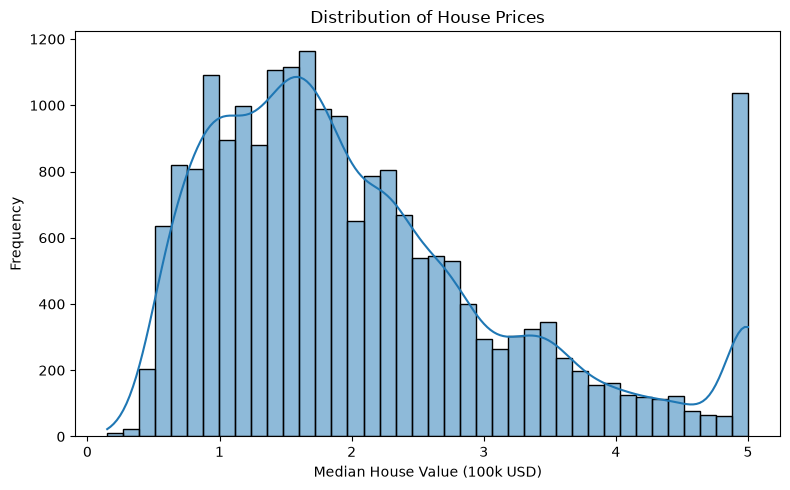

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["MedHouseVal"],
    bins=40,
    kde=True
)

plt.title("Distribution of House Prices")
plt.xlabel("Median House Value (100k USD)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()
#This code draws a histogram of the MedHouseVal column to show how house prices are distributed.
# It uses 40 bins and adds a smooth KDE curve so you can see the overall shape more easily.
# Then it adds a title and axis labels, adjusts the spacing, and displays the plot.
# In plain terms: it helps you quickly see where most house values fall, whether the data is skewed, and if there are unusual values.

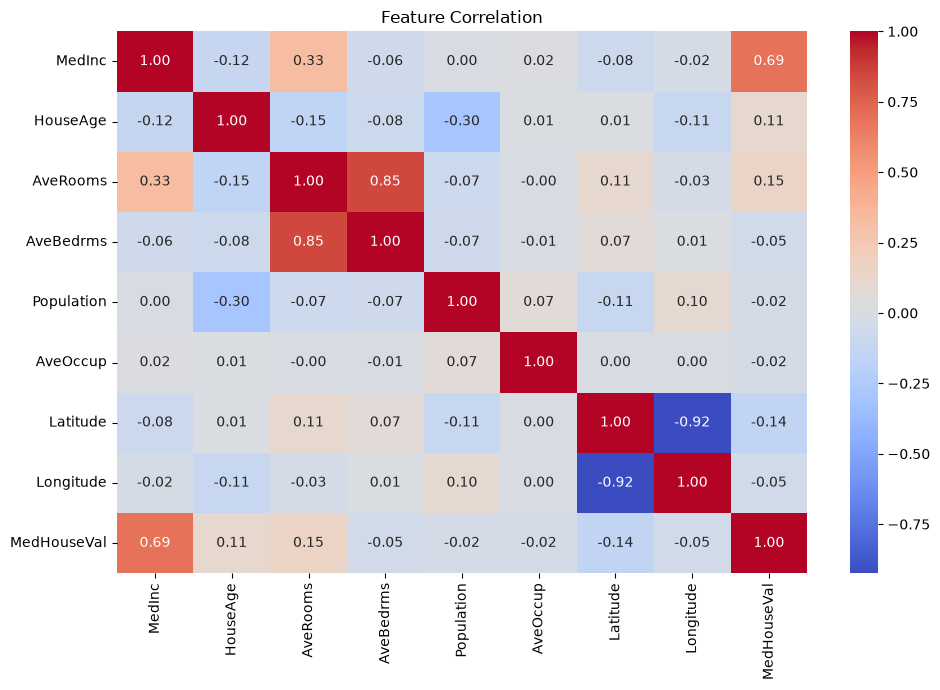

In [ ]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation")

plt.tight_layout()
plt.show()
#his code makes a correlation heatmap for numeric columns.
# Colors show positive/negative relationships, and the numbers show exact correlation values rounded to 2 decimals.
# It helps you quickly spot which features move together.

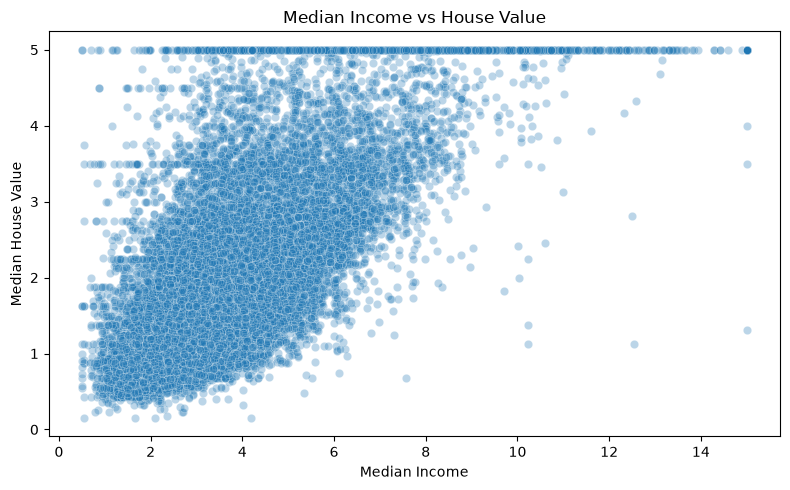

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="MedInc",
    y="MedHouseVal",
    alpha=0.3
)

plt.title("Median Income vs House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.tight_layout()
plt.show()
#This scatterplot shows median income vs. house value.
# Each dot is one area, and alpha=0.3 makes points transparent so dense clusters are easier to see.
# It helps you spot the overall trend (usually higher income → higher value) and any outliers or spread.

In [29]:
correlations = df.corr(numeric_only=True)["MedHouseVal"]

correlations = correlations.sort_values(
    ascending=False
)

print(correlations)

MedHouseVal    1.000000
MedInc         0.688075
AveRooms       0.151948
HouseAge       0.105623
AveOccup      -0.023737
Population    -0.024650
Longitude     -0.045967
AveBedrms     -0.046701
Latitude      -0.144160
Name: MedHouseVal, dtype: float64


In [30]:
X = df.drop(columns="MedHouseVal")

y = df["MedHouseVal"]

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (16512, 8)
Test shape: (4128, 8)


In [32]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

In [33]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R2:", linear_r2)

MAE: 0.5332001304956565
RMSE: 0.7455813830127764
R2: 0.5757877060324508


In [34]:
from sklearn.linear_model import Ridge

ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

In [35]:
ridge_mae = mean_absolute_error(
    y_test,
    ridge_predictions
)

ridge_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_predictions)
)

ridge_r2 = r2_score(
    y_test,
    ridge_predictions
)

print("MAE:", ridge_mae)
print("RMSE:", ridge_rmse)
print("R2:", ridge_r2)

MAE: 0.5331931195789734
RMSE: 0.7455567442814779
R2: 0.5758157428913684


In [36]:
from sklearn.linear_model import Lasso

lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=0.01, max_iter=10000)
)

lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_test)

In [37]:
lasso_mae = mean_absolute_error(
    y_test,
    lasso_predictions
)

lasso_rmse = np.sqrt(
    mean_squared_error(y_test, lasso_predictions)
)

lasso_r2 = r2_score(
    y_test,
    lasso_predictions
)

print("MAE:", lasso_mae)
print("RMSE:", lasso_rmse)
print("R2:", lasso_r2)

MAE: 0.5353261423609053
RMSE: 0.7404423656125414
R2: 0.5816154300698727


In [38]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge",
        "Lasso"
    ],

    "MAE": [
        linear_mae,
        ridge_mae,
        lasso_mae
    ],

    "RMSE": [
        linear_rmse,
        ridge_rmse,
        lasso_rmse
    ],

    "R2": [
        linear_r2,
        ridge_r2,
        lasso_r2
    ]
})

print(results.round(4))

               Model     MAE    RMSE      R2
0  Linear Regression  0.5332  0.7456  0.5758
1              Ridge  0.5332  0.7456  0.5758
2              Lasso  0.5353  0.7404  0.5816


In [39]:
error_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": linear_predictions
})

error_df["Error"] = (
    error_df["Actual"] - error_df["Predicted"]
)

error_df["Absolute Error"] = (
    error_df["Error"].abs()
)

print(error_df.head(10).round(3))

       Actual  Predicted  Error  Absolute Error
20046   0.477      0.719 -0.242           0.242
3024    0.458      1.764 -1.306           1.306
15663   5.000      2.710  2.290           2.290
20484   2.186      2.839 -0.653           0.653
9814    2.780      2.605  0.175           0.175
13311   1.587      2.012 -0.425           0.425
7113    1.982      2.646 -0.664           0.664
7668    1.575      2.169 -0.594           0.594
18246   3.400      2.741  0.659           0.659
5723    4.466      3.916  0.550           0.550


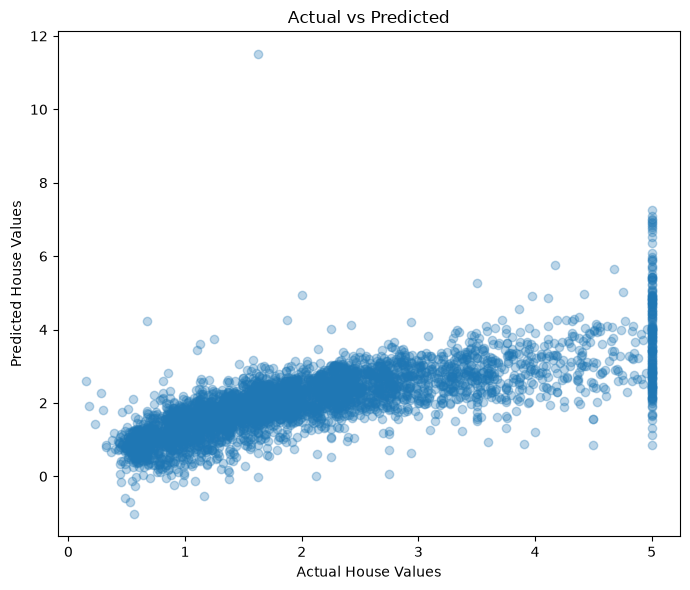

In [40]:
plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.3
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")

plt.title("Actual vs Predicted")

plt.tight_layout()
plt.show()

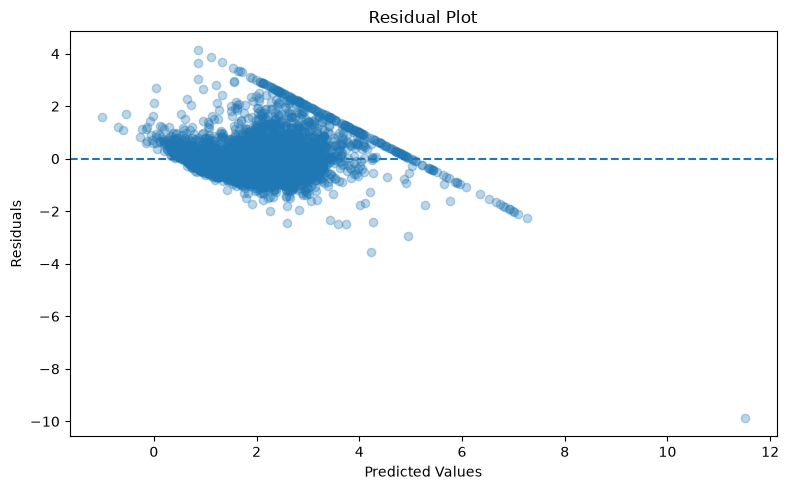

In [41]:
residuals = y_test - linear_predictions

plt.figure(figsize=(8, 5))

plt.scatter(
    linear_predictions,
    residuals,
    alpha=0.3
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.tight_layout()
plt.show()

In [42]:
import joblib
from pathlib import Path

model_path = Path("../models/linear_regression_model.pkl")

model_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(
    linear_model,
    model_path
)

['..\\models\\linear_regression_model.pkl']